Parsed DataFrame Preview:
         Date  Location  PM2.5Level  Air Quality_Category
0  20-09-2026      city         NaN                    65
1  21-09-2026  industry         NaN                    76
2  22-09-2026  industry         NaN                    89
3  23-09-2022  industry         NaN                    23
4  24-09-2026      city         NaN                    90


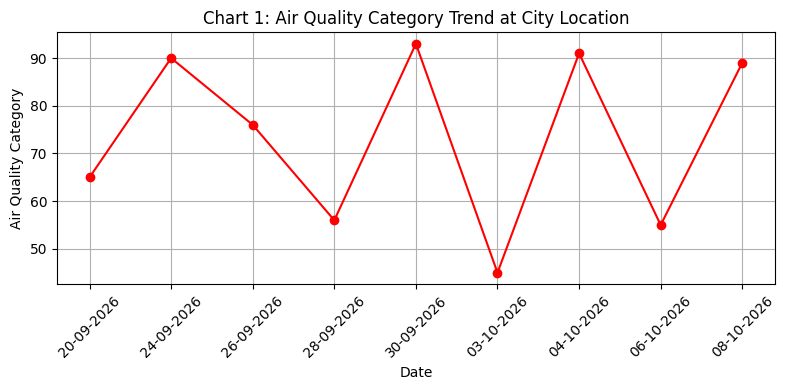

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Define the correct column names based on the data structure
custom_columns = ['Date', 'Location', 'PM2.5Level', 'Air Quality_Category']

# Load the dataset skipping the malformed header row and manually specifying correct columns
df = pd.read_csv('/content/Air_Quality.csv', names=custom_columns, skiprows=1, sep=',')

# Safely strip any whitespaces from string values in 'Location' and other columns
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].astype(str).str.strip()

print("Parsed DataFrame Preview:")
print(df.head())

# --- DATA PREPARATION & AGGREGATION ---

# Filter data for just the city location
city_center_data = df[df['Location'] == 'city']

# --- THE 5 REQUIRED CHARTS ---

# Chart 1: Line Chart (Tracking Air Quality Category over time at city location)
plt.figure(figsize=(8, 4))
plt.plot(city_center_data['Date'], city_center_data['Air Quality_Category'], marker='o', color='red')
plt.title('Chart 1: Air Quality Category Trend at City Location')
plt.xlabel('Date')
plt.ylabel('Air Quality Category')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

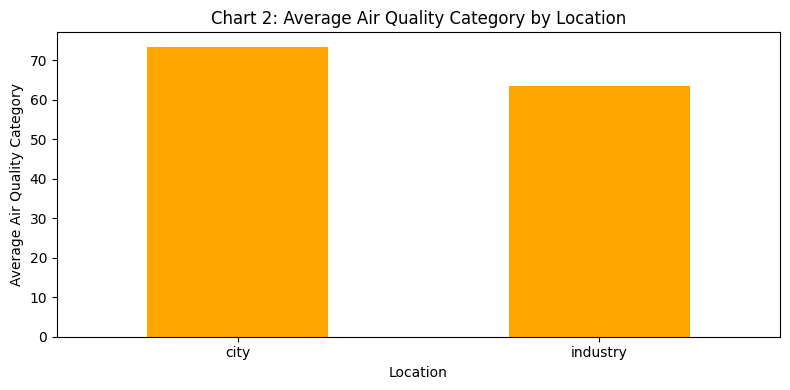

In [10]:
# Calculate average Air Quality Category by location
avg_pollution = df.groupby('Location')[['Air Quality_Category']].mean()

# Chart 2: Bar Chart (Comparing average Air Quality Category by location)
plt.figure(figsize=(8, 4))
avg_pollution['Air Quality_Category'].plot(kind='bar', color='orange')
plt.title('Chart 2: Average Air Quality Category by Location')
plt.xlabel('Location')
plt.ylabel('Average Air Quality Category')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

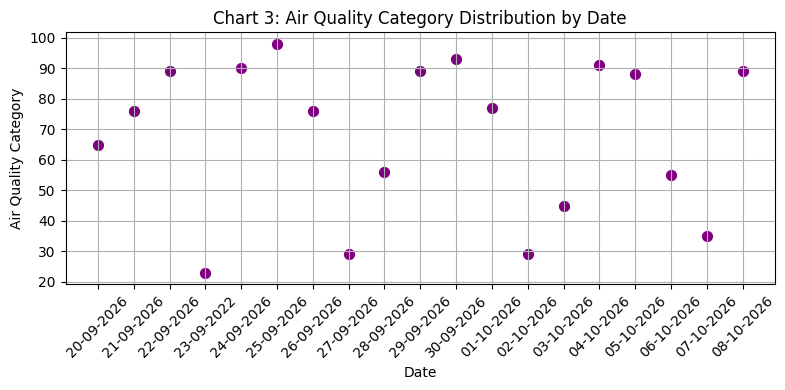

In [13]:
# Drop NaN values specifically from the columns we are plotting to avoid matplotlib axis conversion errors
plot_data = df.dropna(subset=['Date', 'Air Quality_Category'])

# Chart 3: Scatter Plot (Distribution of Air Quality Categories over Dates)
plt.figure(figsize=(8, 4))
plt.scatter(plot_data['Date'], plot_data['Air Quality_Category'], color='purple', s=50)
plt.title('Chart 3: Air Quality Category Distribution by Date')
plt.xlabel('Date')
plt.ylabel('Air Quality Category')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

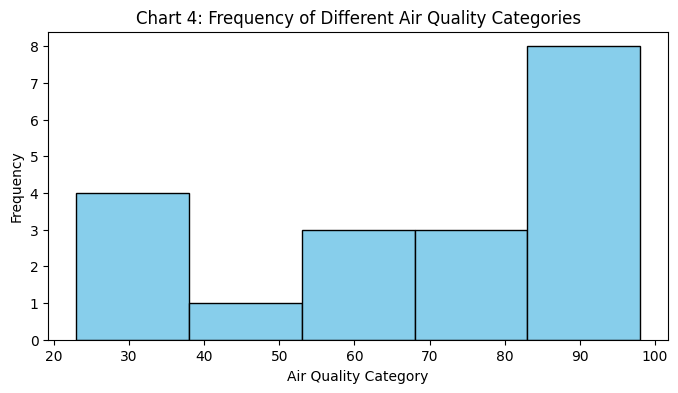

In [16]:
# Chart 4: Histogram (Distribution of all Air Quality Category readings)
plt.figure(figsize=(8, 4))
plt.hist(df['Air Quality_Category'].astype(float), bins=5, color='skyblue', edgecolor='black')
plt.title('Chart 4: Frequency of Different Air Quality Categories')
plt.xlabel('Air Quality Category')
plt.ylabel('Frequency')
plt.show()

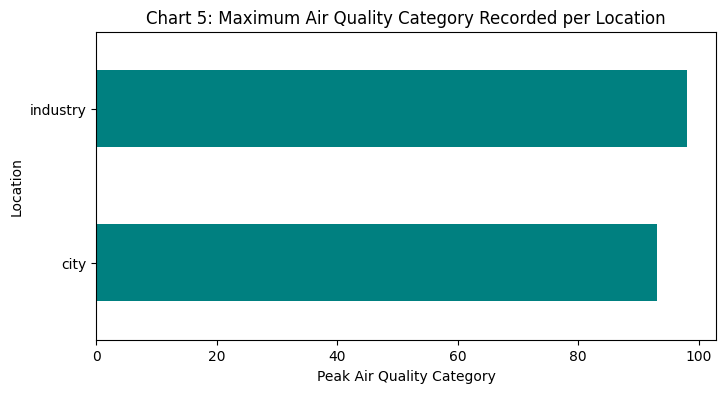

In [19]:
# Chart 5: Horizontal Bar Chart (Max Air Quality Category recorded per location)
plt.figure(figsize=(8, 4))
df.groupby('Location')['Air Quality_Category'].max().plot(kind='barh', color='teal')
plt.title('Chart 5: Maximum Air Quality Category Recorded per Location')
plt.xlabel('Peak Air Quality Category')
plt.ylabel('Location')
plt.show()

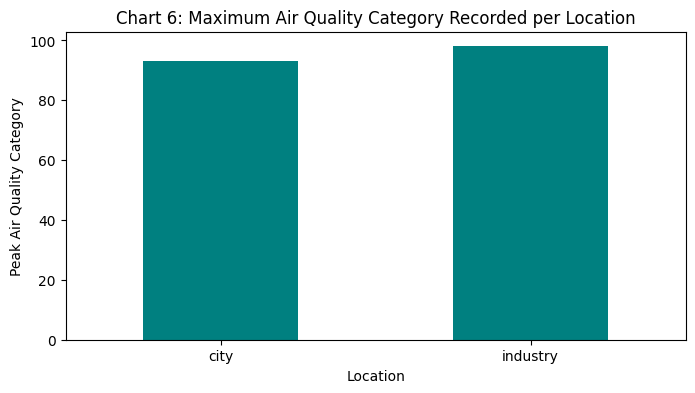

In [21]:
# Chart 6: Vertical Bar Chart (Max Air Quality Category recorded per location)
plt.figure(figsize=(8, 4))
df.groupby('Location')['Air Quality_Category'].max().plot(kind='bar', color='teal')
plt.title('Chart 6: Maximum Air Quality Category Recorded per Location')
plt.xlabel('Location')
plt.ylabel('Peak Air Quality Category')
plt.xticks(rotation=0)
plt.show()

In [22]:
#1. Define the exact text for your Week 2 README file
readme_text = """# Week 2: Data Handling, Visualisation & AI Prompting
## Overview
This folder contains my Week 2 deliverables for the II CSE(AI&ML) – A Department Activity Plan. The primary focus of this week is Exploratory Data Analysis (EDA) on campus energy and city air-quality datasets, alongside AI prompt engineering and collaborative Git workflows.

## Week 2 Deliverables
* **EDA Notebook:** A Google Colab notebook using `pandas` and `matplotlib` that cleans, groups, and filters dataset. It includes 5 labelled charts and 5 written data insights.
* **AI Application Mapping:** Classification of 10 real-world systems into Rule-based, ML, DL, or Generative AI categories.
* **Prompt Engineering Portfolio:** A structured document containing 10 AI prompts (zero-shot, role, constraint, etc.), their outputs, and improvement notes for data-summary tasks.
* **Git Branching:** Proof of 2 branches and 1 merged pull request executed on this repository.

## How to Run the Code in Google Colab
1. Open the `.ipynb` notebook file in this repository.
2. Click the **"Open in Colab"** badge at the top of the file.
3. Ensure the dataset CSV file is uploaded to the Colab session storage before running the cells.
4. Run all cells to generate the 5 data visualisations.

## Technologies Used
* **Python Libraries:** `pandas`, `matplotlib`
* **Tools:** Google Colab, Git, GitHub
"""


# 2. Write the text into a new file named README.md
with open("README.md", "w") as file:
    file.write(readme_text)

# 3. Tell Google Colab to trigger a download of the file to your computer
from google.colab import files
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>